# Assignment 2 – Data Science Tools & Techniques (MS DS)
## Q1: Data Distributions and Their Applications
**Student:** Taha Naqvi  |  **Datasets:** (1) `dataset.csv` (tabular, 5,050 rows × 20 columns), (2) CIFAR-10

**Contents**
1. Setup
2. Task 1 – Data Analysis (cleaning, EDA, distribution identification)
3. Task 2 – Case Study with CIFAR-10 (structure, 3 classes, features, distributions, IID vs Non-IID)
4. Summary

## 0. Setup

In [1]:
import os, io, pickle, tarfile, tempfile, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.signal import find_peaks

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11, "axes.labelsize": 10})
RNG = np.random.default_rng(42)          # fixed seed -> reproducible random samples

CSV_PATH = "Taha Naqvi - The Attached Dataset 2.csv"   # provided dataset (keep next to notebook)
FIG_DIR  = os.environ.get("FIG_DIR")                    # optional: also save figures (used for the report)
if FIG_DIR: os.makedirs(FIG_DIR, exist_ok=True)

def show(name):
    """Optionally save the current figure, then display it."""
    if FIG_DIR: plt.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()

---
# Task 1 – Data Analysis (Dataset #1)
## 1.1 Load and first look

In [2]:
raw = pd.read_csv(CSV_PATH)
print("Shape:", raw.shape)
display(raw.head())
print()
raw.info()

Shape: (5050, 20)


,id,age,gender,education,marital_status,workclass,occupation,hours_per_week,capital_gain,capital_loss,native_country,annual_income,loan_status,experience_years,job_satisfaction,bmi,smoking_status,physical_activity,credit_score,disease_risk
0,1,63,Female,Masters,Married,Unemployed,Other-service,57,28219,7604,us,80471,denied,26,1,21.1,occasional,medium,759,0
1,2,20,Female,PhD,Married,Government,NaN,98,26959,8738,NaN,83789,approved,34,3,23.9,smoker,low,730,0
2,3,46,Female,Bachelors,Divorced,Unemployed,Tech-support,8,15621,7180,India,93380,approved,5,4,28.4,non-smoker,low,460,0
3,4,52,Other,Masters,Single,Government,Other-service,9,26022,8588,us,41035,denied,19,5,26.6,occasional,medium,464,0
4,5,56,Female,Masters,Single,Self-Employed,Prof-specialty,49,3075,2399,UK,69893,denied,19,1,24.5,smoker,high,NaN,0



<class 'pandas.DataFrame'>
RangeIndex: 5050 entries, 0 to 5049
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5050 non-null   int64  
 1   age                5050 non-null   int64  
 2   gender             5050 non-null   str    
 3   education          5050 non-null   str    
 4   marital_status     5050 non-null   str    
 5   workclass          4798 non-null   str    
 6   occupation         4798 non-null   str    
 7   hours_per_week     5050 non-null   int64  
 8   capital_gain       5050 non-null   int64  
 9   capital_loss       5050 non-null   int64  
 10  native_country     4796 non-null   str    
 11  annual_income      4799 non-null   str    
 12  loan_status        5050 non-null   str    
 13  experience_years   5050 non-null   int64  
 14  job_satisfaction   5050 non-null   int64  
 15  bmi                4800 non-null   float64
 16  smoking_status     5050 non-null  

**Observation.** `annual_income` and `credit_score` are loaded as *text* (`object`/`str`) although they should be numeric. That alone signals that non-numeric tokens are hiding in them. Section 1.2 audits all quality problems before anything is changed.

## 1.2 Data-quality audit

In [3]:
audit = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing (NaN)": raw.isna().sum(),
    "missing %": (raw.isna().mean() * 100).round(2),
    "'unknown' tokens": [(raw[c] == "unknown").sum() if raw[c].dtype != "int64" and raw[c].dtype != "float64" else 0 for c in raw.columns],
    "n unique": raw.nunique(),
})
display(audit)

print("Exact duplicate rows (all 20 columns):", raw.duplicated().sum())
print("Duplicate ids:", raw["id"].duplicated().sum(), "(every duplicated id is a full-row copy)")
print("\nnative_country labels:", raw["native_country"].value_counts(dropna=False).to_dict())
inc = pd.to_numeric(raw["annual_income"], errors="coerce")
print("\nNegative annual_income values:", (inc < 0).sum())

,dtype,missing (NaN),missing %,'unknown' tokens,n unique
id,int64,0,0.00,0,5000
age,int64,0,0.00,0,52
gender,str,0,0.00,0,3
education,str,0,0.00,0,4
marital_status,str,0,0.00,0,4
workclass,str,252,4.99,0,4
occupation,str,252,4.99,0,7
hours_per_week,int64,0,0.00,0,115
capital_gain,int64,0,0.00,0,4753
capital_loss,int64,0,0.00,0,3929


Exact duplicate rows (all 20 columns): 49
Duplicate ids: 50 (every duplicated id is a full-row copy)

native_country labels: {'UK': 632, 'us': 613, 'USA': 606, 'Germany': 606, 'Canada': 604, 'U.S.': 590, 'Mexico': 576, 'India': 569, nan: 254}

Negative annual_income values: 12


**Problems found**

| # | Problem | Where |
|---|---------|-------|
| 1 | Missing values (NaN, ~5 % each) | `workclass`, `occupation`, `native_country`, `annual_income`, `bmi`, `credit_score` |
| 2 | Hidden missing values: the string `"unknown"` | `annual_income`, `credit_score` (this is why they are text) |
| 3 | Inconsistent category labels: `us`, `USA`, `U.S.` all mean the same country | `native_country` |
| 4 | Impossible values: negative income, `hours_per_week` up to 391 (a week has 168 h), BMI up to 204 | `annual_income`, `hours_per_week`, `bmi` |
| 5 | Exact duplicate rows | whole table |

## 1.3 Cleaning
Order matters. Hidden missing values and impossible values are converted to `NaN` first, duplicates are removed, outliers are treated on the *observed* values, and imputation comes last. This way the imputed values are never computed from corrupted numbers.

**Step 1 – Remove duplicates**

In [4]:
df = raw.copy()
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {n0}  |  removed duplicates: {n0 - len(df)}  |  rows after: {len(df)}")

Rows before: 5050  |  removed duplicates: 49  |  rows after: 5001


**Step 2 – Standardise types and labels** (`unknown` → NaN, text → numeric, unify country names, negative income → NaN)

In [5]:
for col in ["annual_income", "credit_score"]:
    df[col] = pd.to_numeric(df[col].replace("unknown", np.nan), errors="coerce")

# unify the three spellings of the United States
df["native_country"] = df["native_country"].replace({"us": "USA", "U.S.": "USA"})

# income cannot be negative -> treat as invalid (missing)
neg = (df["annual_income"] < 0).sum()
df.loc[df["annual_income"] < 0, "annual_income"] = np.nan
print("Negative incomes set to NaN:", neg)
print("native_country now:", df["native_country"].value_counts(dropna=False).to_dict())
print("\nMissing values after step 2:")
print(df.isna().sum()[lambda s: s > 0].to_string())

Negative incomes set to NaN: 12
native_country now: {'USA': 1791, 'UK': 624, 'Canada': 599, 'Germany': 599, 'Mexico': 572, 'India': 566, nan: 250}

Missing values after step 2:
workclass         250
occupation        250
native_country    250
annual_income     361
bmi               250
credit_score      349


**Step 3 – Detect outliers (IQR rule)**
A value is an outlier if it lies outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`. Discrete scales (`job_satisfaction` 1–5, `disease_risk` 0/1) are excluded since outliers are meaningless there.

,lower fence,upper fence,min,max,# outliers,% outliers
feature,,,,,,
age,-8.0,96.0,18.0,69.0,0,0.00
hours_per_week,-43.0,149.0,5.0,391.0,20,0.40
capital_gain,-23392.5,74435.5,3.0,49994.0,0,0.00
capital_loss,-5204.5,15071.5,0.0,9998.0,0,0.00
experience_years,-22.0,66.0,0.0,44.0,0,0.00
bmi,13.5,40.7,9.2,204.0,49,1.03
annual_income,1965.4,139478.4,170.0,2292645.0,48,1.03
credit_score,27.0,1131.0,300.0,849.0,0,0.00


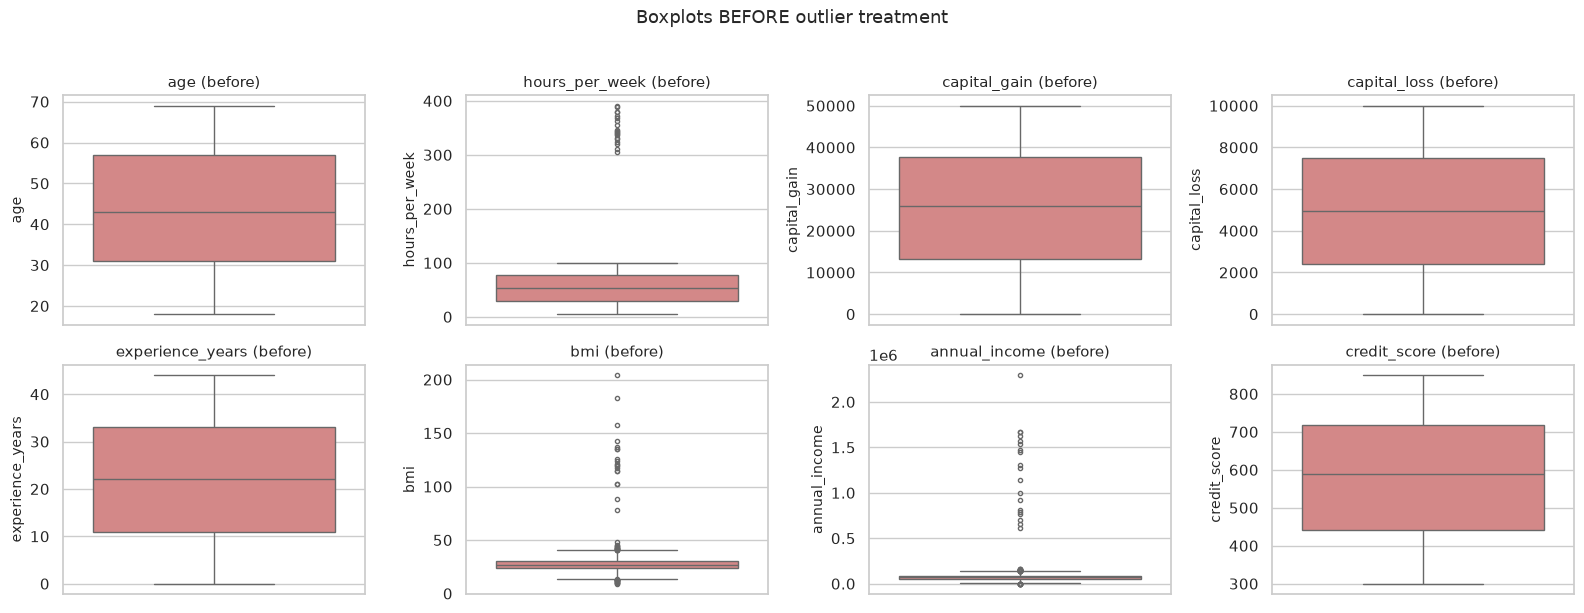

In [6]:
num_cols = ["age", "hours_per_week", "capital_gain", "capital_loss", "experience_years",
            "bmi", "annual_income", "credit_score"]          # continuous / count features

def iqr_fences(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for c in num_cols:
    lo, hi = iqr_fences(df[c].dropna())
    out = ((df[c] < lo) | (df[c] > hi)).sum()
    rows.append({"feature": c, "lower fence": round(lo, 1), "upper fence": round(hi, 1),
                 "min": df[c].min(), "max": df[c].max(), "# outliers": out,
                 "% outliers": round(100 * out / df[c].notna().sum(), 2)})
outlier_tbl = pd.DataFrame(rows).set_index("feature")
display(outlier_tbl)

# boxplots BEFORE treatment (each feature on its own scale)
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#e07b7b", flierprops=dict(marker="o", markersize=3))
    ax.set_title(f"{c} (before)")
plt.suptitle("Boxplots BEFORE outlier treatment", y=1.02, fontsize=13)
plt.tight_layout(); show("t1_box_before")

**Step 4 – Treat outliers.** Only three features have outliers, and in all three the extreme values are physically impossible: `hours_per_week` of 306–391 (a week has 168 h), BMI up to 204, and incomes of up to 2.3 million next to a median of about 70 k. They are data-entry errors, not real extremes. 

I replace them with `NaN` and impute them in Step 5 like any other missing value. I avoided *winsorising* (clipping to the IQR fence) on purpose. For `hours_per_week` the fence is 149 h, so clipping would create an artificial pile of 20 rows at an impossible value of 149 h and distort exactly the distribution shape this assignment studies. Deleting the rows would also waste the other 19 valid columns of each row.

In [7]:
df_before = df.copy()                                   # snapshot (for before/after comparison)
for c in num_cols:
    lo, hi = iqr_fences(df[c].dropna())
    mask = (df[c] < lo) | (df[c] > hi)
    df.loc[mask, c] = np.nan                            # outlier -> missing
print("Missing values per column after flagging outliers:")
print(df.isna().sum()[lambda s: s > 0].to_string())
df_pre_impute = df.copy()                               # observed values only (no outliers, no imputation)

Missing values per column after flagging outliers:
workclass         250
occupation        250
hours_per_week     20
native_country    250
annual_income     409
bmi               299
credit_score      349


**Step 5 – Impute missing values**
* Numeric (`bmi`, `annual_income`, `credit_score`, `hours_per_week`): **random draw from the observed values** (seeded, so it is reproducible). Median imputation is the usual default, but here it is harmful: `credit_score` has 349 missing values (7 %), and filling all of them with one number would create a tall artificial spike in an otherwise flat distribution. Random draws from the observed values keep the shape (mean, spread, skewness) of each feature intact.
* Categorical (`workclass`, `occupation`, `native_country`): a separate **`Unknown`** category. Missingness is about 5 %, and inventing a mode would silently bias the category counts.

In [8]:
def impute_by_sampling(s, rng):
    """Fill NaNs with random draws from the observed values of the same column."""
    s = s.copy(); miss = s.isna()
    s[miss] = rng.choice(s[~miss].to_numpy(), size=miss.sum(), replace=True)
    return s

for c in ["bmi", "annual_income", "credit_score", "hours_per_week"]:
    df[c] = impute_by_sampling(df[c], RNG)
for c in ["workclass", "occupation", "native_country"]:
    df[c] = df[c].fillna("Unknown")

df["credit_score"]  = df["credit_score"].round().astype(int)
df["annual_income"] = df["annual_income"].round().astype(int)
df["hours_per_week"] = df["hours_per_week"].round().astype(int)
for c in ["age", "capital_gain", "capital_loss", "experience_years"]:   # restore integer type (NaN step made them float)
    df[c] = df[c].astype(int)

print("Remaining missing values:", int(df.isna().sum().sum()))
print("Remaining duplicates   :", int(df.drop(columns="id").duplicated().sum()))
print("Final shape            :", df.shape)
assert df.isna().sum().sum() == 0 and df.drop(columns="id").duplicated().sum() == 0
display(df.head())

Remaining missing values: 0
Remaining duplicates   : 0
Final shape            : (5001, 20)


,id,age,gender,education,marital_status,workclass,occupation,hours_per_week,capital_gain,capital_loss,native_country,annual_income,loan_status,experience_years,job_satisfaction,bmi,smoking_status,physical_activity,credit_score,disease_risk
0,1,63,Female,Masters,Married,Unemployed,Other-service,57,28219,7604,USA,80471,denied,26,1,21.1,occasional,medium,759,0
1,2,20,Female,PhD,Married,Government,Unknown,98,26959,8738,Unknown,83789,approved,34,3,23.9,smoker,low,730,0
2,3,46,Female,Bachelors,Divorced,Unemployed,Tech-support,8,15621,7180,India,93380,approved,5,4,28.4,non-smoker,low,460,0
3,4,52,Other,Masters,Single,Government,Other-service,9,26022,8588,USA,41035,denied,19,5,26.6,occasional,medium,464,0
4,5,56,Female,Masters,Single,Self-Employed,Prof-specialty,49,3075,2399,UK,69893,denied,19,1,24.5,smoker,high,561,0


**Boxplots after cleaning** (outliers removed, missing values imputed)

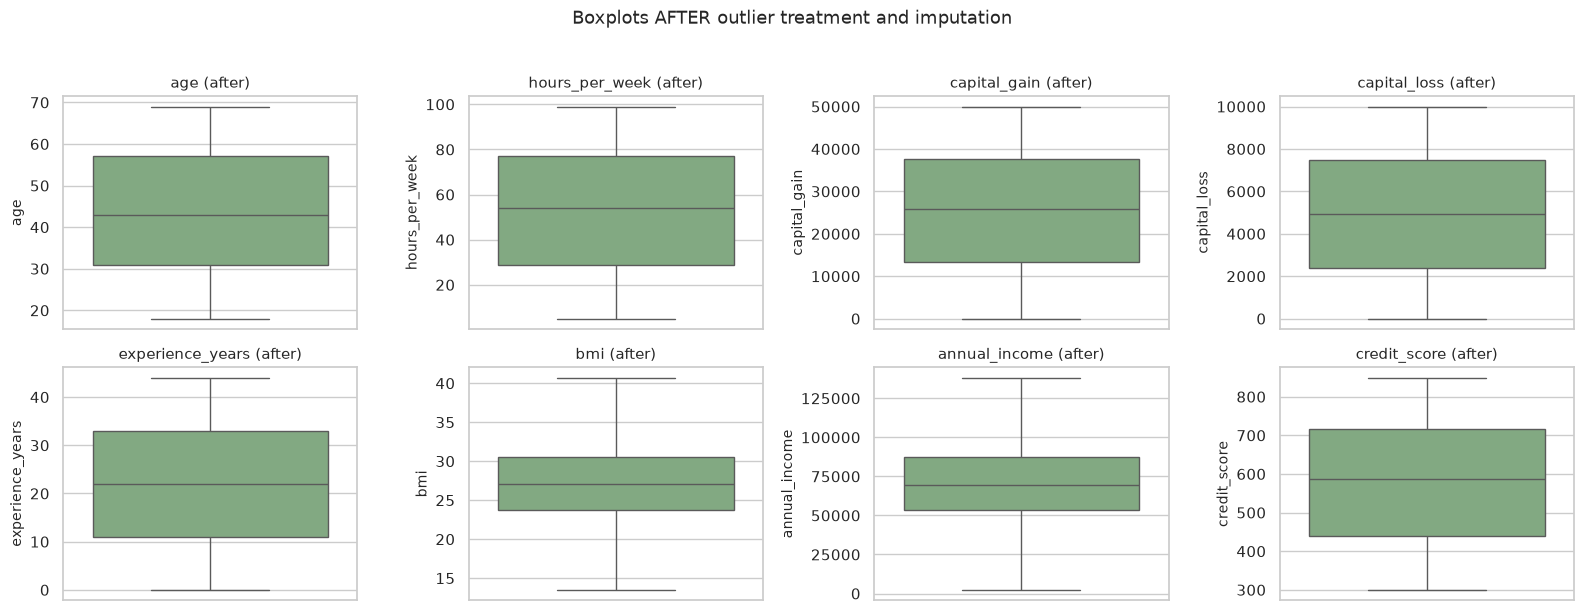

,max before,max after,std before,std after
age,69.0,69.0,14.9,14.9
hours_per_week,391.0,99.0,33.3,27.5
capital_gain,49994.0,49994.0,14471.5,14471.5
capital_loss,9998.0,9998.0,2915.7,2915.7
experience_years,44.0,44.0,12.9,12.9
bmi,204.0,40.7,8.3,4.8
annual_income,2292645.0,138130.0,82806.2,24434.4
credit_score,849.0,849.0,159.5,160.0


In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#7bb07b", flierprops=dict(marker="o", markersize=3))
    ax.set_title(f"{c} (after)")
plt.suptitle("Boxplots AFTER outlier treatment and imputation", y=1.02, fontsize=13)
plt.tight_layout(); show("t1_box_after")

cmp = pd.DataFrame({"max before": df_before[num_cols].max(), "max after": df[num_cols].max(),
                    "std before": df_before[num_cols].std().round(1), "std after": df[num_cols].std().round(1)})
display(cmp)

**Sanity check on imputation.** The distribution of the final data (line) should match the distribution of the genuinely observed values (shaded). If imputation had distorted a feature, the two would differ.

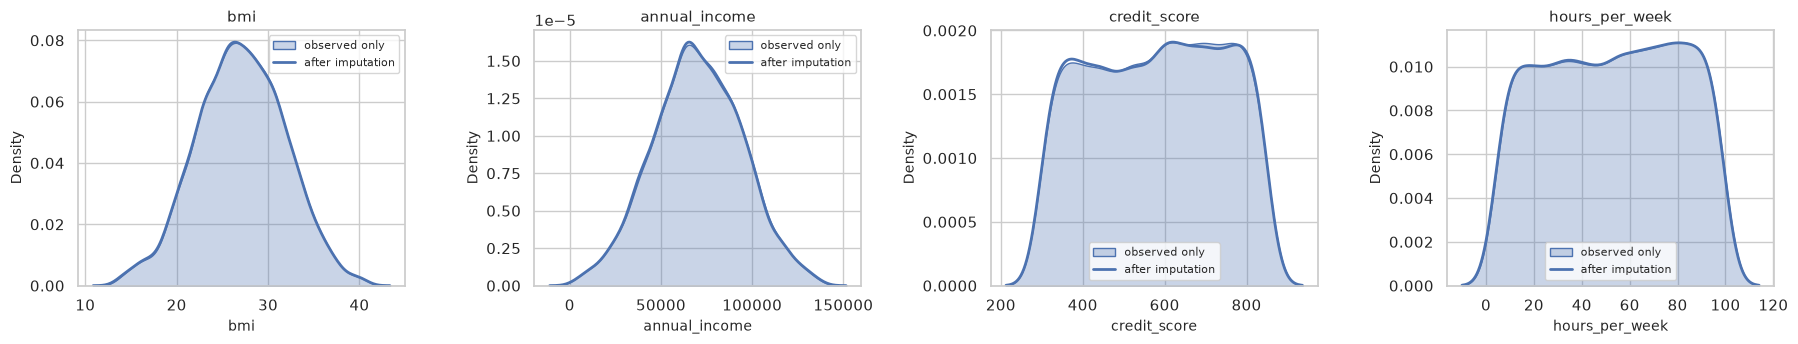

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, c in zip(axes, ["bmi", "annual_income", "credit_score", "hours_per_week"]):
    sns.kdeplot(df_pre_impute[c].dropna(), ax=ax, label="observed only", fill=True, alpha=.3)
    sns.kdeplot(df[c], ax=ax, label="after imputation", lw=2)
    ax.set_title(c); ax.legend(fontsize=8)
plt.tight_layout(); show("t1_imputation_check")

## 1.4 Exploratory Data Analysis
### Summary statistics (mean, median, variance and more)

In [11]:
summary = pd.DataFrame({
    "mean": df[num_cols + ["job_satisfaction"]].mean(),
    "median": df[num_cols + ["job_satisfaction"]].median(),
    "variance": df[num_cols + ["job_satisfaction"]].var(),
    "std": df[num_cols + ["job_satisfaction"]].std(),
    "min": df[num_cols + ["job_satisfaction"]].min(),
    "max": df[num_cols + ["job_satisfaction"]].max(),
    "skewness": df[num_cols + ["job_satisfaction"]].skew(),
    "excess kurtosis": df[num_cols + ["job_satisfaction"]].kurt(),
}).round(3)
pd.options.display.float_format = "{:,.3f}".format
display(summary)
pd.reset_option("display.float_format")

print("Categorical features – counts")
cat_cols = ["gender", "education", "marital_status", "workclass", "occupation",
            "native_country", "loan_status", "smoking_status", "physical_activity"]
for c in cat_cols:
    print(f"  {c:16s}", df[c].value_counts().to_dict())
print("\n  disease_risk (target) :", df["disease_risk"].value_counts().to_dict(),
      f"-> {df['disease_risk'].mean():.1%} positive")

,mean,median,variance,std,min,max,skewness,excess kurtosis
age,43.589,43.000,223.190,14.940,18.000,69.000,-0.003,-1.184
hours_per_week,52.631,54.000,758.442,27.540,5.000,99.000,-0.049,-1.207
capital_gain,"25,530.286","25,919.000","209,424,761.510","14,471.516",3.000,"49,994.000",-0.040,-1.181
capital_loss,"4,947.836","4,946.000","8,501,052.042","2,915.656",0.000,"9,998.000",0.023,-1.226
experience_years,21.994,22.000,165.600,12.869,0.000,44.000,0.010,-1.189
bmi,27.058,27.100,23.279,4.825,13.500,40.700,-0.027,-0.210
annual_income,"70,159.713","69,737.000","597,040,364.907","24,434.409","2,344.000","138,130.000",0.004,-0.246
credit_score,579.363,588.000,"25,605.420",160.017,300.000,849.000,-0.053,-1.205
job_satisfaction,3.010,3.000,2.012,1.419,1.000,5.000,-0.016,-1.307


Categorical features – counts
  gender           {'Female': 2504, 'Male': 2411, 'Other': 86}
  education        {'PhD': 1288, 'High School': 1251, 'Masters': 1236, 'Bachelors': 1226}
  marital_status   {'Divorced': 1343, 'Widowed': 1235, 'Married': 1234, 'Single': 1189}
  workclass        {'Unemployed': 1227, 'Government': 1199, 'Self-Employed': 1175, 'Private': 1150, 'Unknown': 250}
  occupation       {'Sales': 714, 'Craft-repair': 690, 'Prof-specialty': 681, 'Machine-op-inspct': 681, 'Tech-support': 674, 'Other-service': 663, 'Exec-managerial': 648, 'Unknown': 250}
  native_country   {'USA': 1791, 'UK': 624, 'Canada': 599, 'Germany': 599, 'Mexico': 572, 'India': 566, 'Unknown': 250}
  loan_status      {'approved': 2558, 'denied': 2443}
  smoking_status   {'smoker': 1707, 'non-smoker': 1672, 'occasional': 1622}
  physical_activity {'high': 1711, 'medium': 1683, 'low': 1607}

  disease_risk (target) : {0: 3445, 1: 1556} -> 31.1% positive


### Distribution plots (histogram + density)

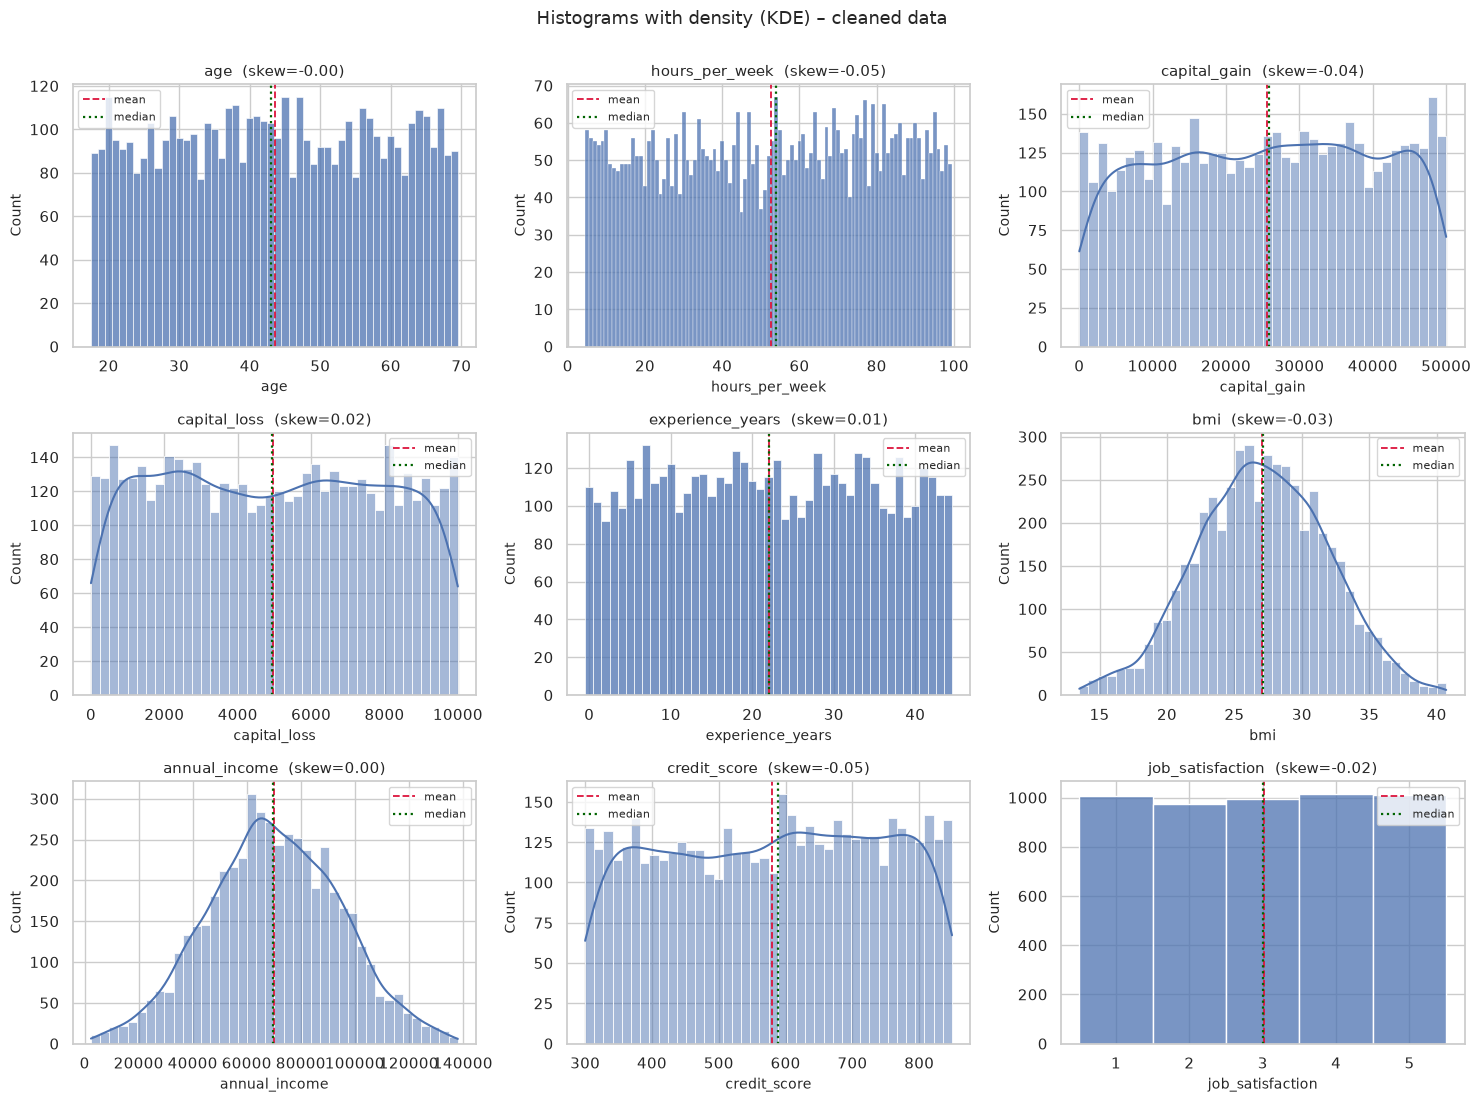

In [12]:
plot_cols = num_cols + ["job_satisfaction"]
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, c in zip(axes.ravel(), plot_cols):
    discrete = df[c].nunique() <= 100 and df[c].dtype.kind == "i"
    sns.histplot(df[c], kde=not discrete, discrete=discrete, bins=None if discrete else 40,
                 ax=ax, color="#4c72b0", edgecolor="white")
    ax.axvline(df[c].mean(), color="crimson", ls="--", lw=1.3, label="mean")
    ax.axvline(df[c].median(), color="darkgreen", ls=":", lw=1.6, label="median")
    ax.set_title(f"{c}  (skew={df[c].skew():.2f})"); ax.legend(fontsize=8)
plt.suptitle("Histograms with density (KDE) – cleaned data", y=1.0, fontsize=13)
plt.tight_layout(); show("t1_hist_grid")

### Boxplots of the cleaned features, split by the target `disease_risk`

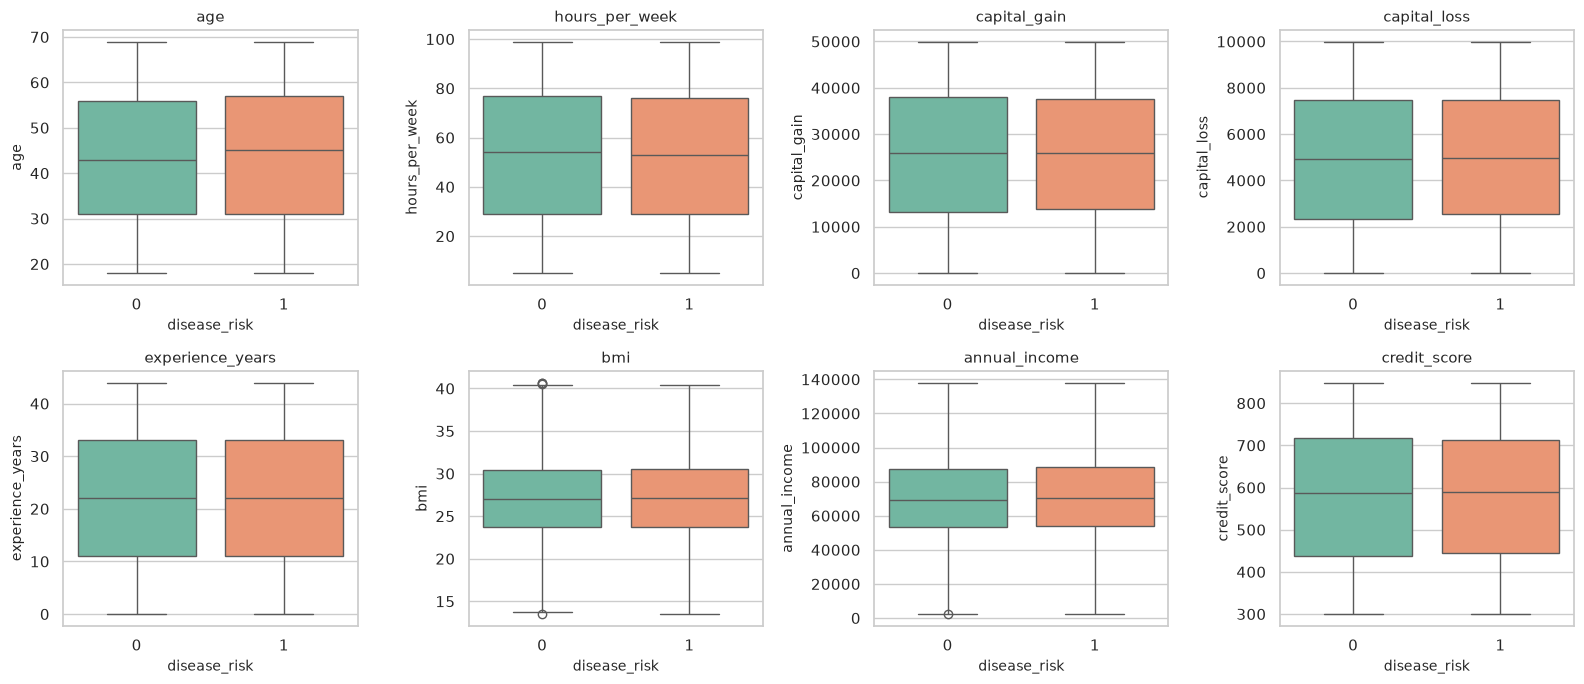

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="disease_risk", y=c, ax=ax, palette="Set2")
    ax.set_title(c)
plt.tight_layout(); show("t1_box_by_target")

### Categorical features

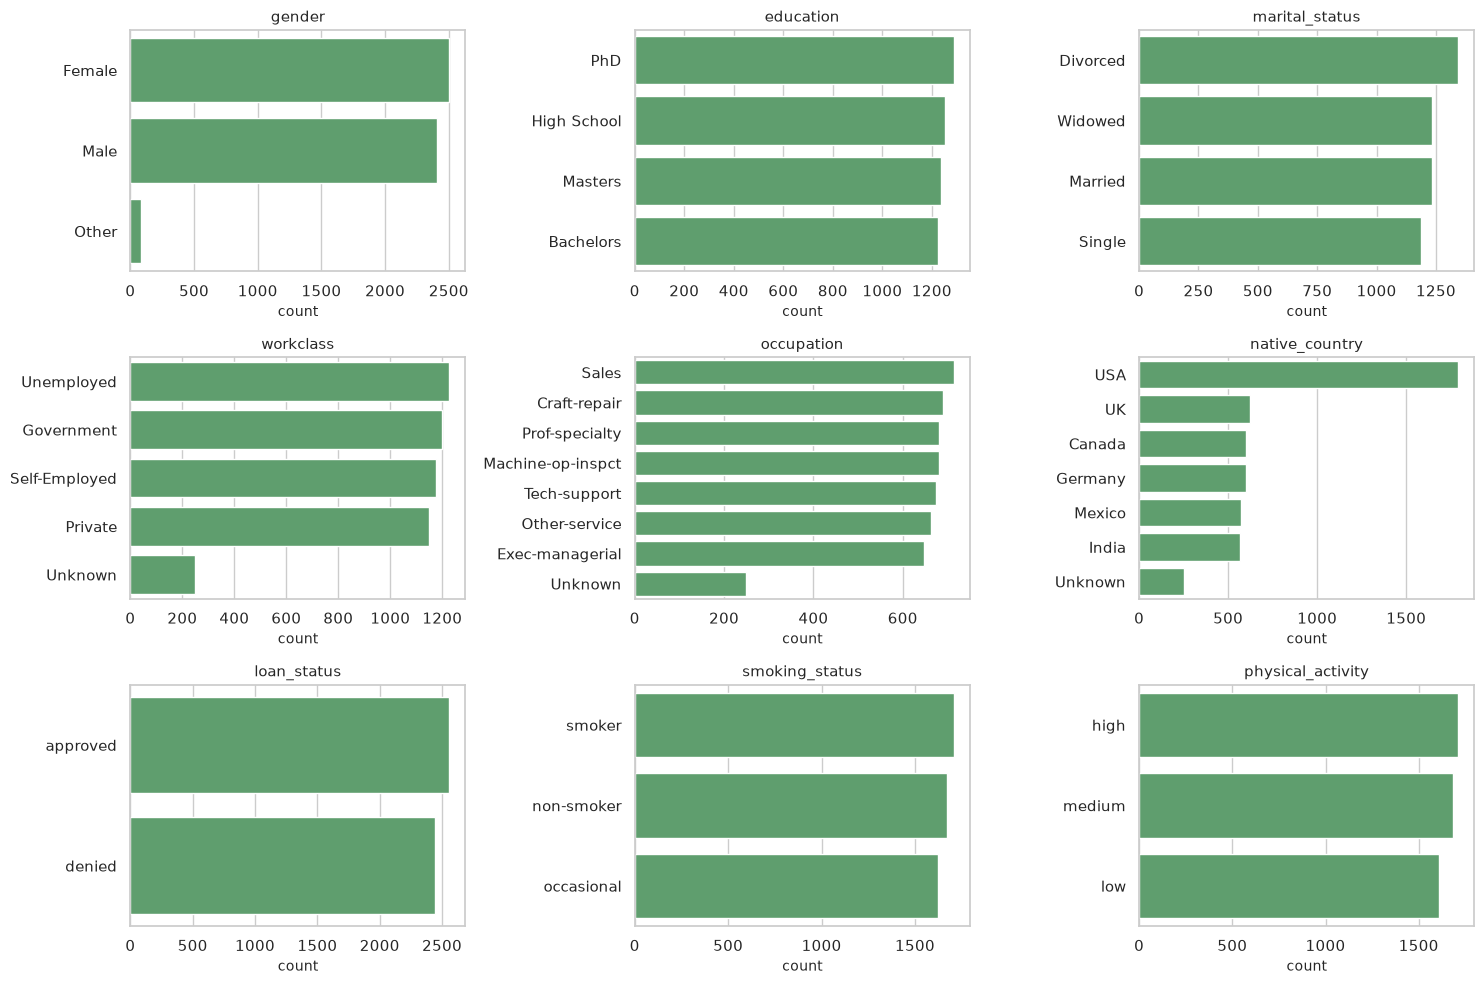

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, c in zip(axes.ravel(), cat_cols):
    order = df[c].value_counts().index
    sns.countplot(data=df, y=c, order=order, ax=ax, color="#55a868")
    ax.set_title(c); ax.set_ylabel("")
plt.tight_layout(); show("t1_cat_counts")

## 1.5 Which features are normal, uniform, skewed or multimodal?
I identify the pattern by combining **three pieces of evidence** instead of eyeballing a histogram:

1. **Shape statistics** – skewness (`≈ 0` symmetric) and excess kurtosis (`≈ 0` normal-like, `≈ −1.2` uniform).
2. **Goodness-of-fit tests** – Kolmogorov–Smirnov (KS) distance to the fitted *uniform* and *normal* distributions. With n ≈ 5,000 the p-values are extremely sensitive, so the KS *distance* `D` is used as the measure of fit (smaller = closer).
3. **Number of density peaks** – modes found in a Gaussian KDE (a peak must be at least 10 % as tall as the highest).

Decision rules (applied in this order): uniform → skewed → multimodal → normal.

In [15]:
def n_modes(x, rel_height=0.10):
    """Count peaks of a Gaussian KDE (peak must reach rel_height * max density)."""
    x = np.asarray(x, float)
    grid = np.linspace(x.min(), x.max(), 512)
    dens = stats.gaussian_kde(x)(grid)
    peaks, _ = find_peaks(dens, height=rel_height * dens.max(), prominence=0.05 * dens.max())
    return len(peaks)

def describe_distribution(x, name=None):
    """Return statistics + a heuristic label for a 1-D numeric sample."""
    x = pd.Series(x).dropna().astype(float)
    sk, ku = stats.skew(x), stats.kurtosis(x)                      # excess kurtosis
    if x.nunique() <= 10:                                          # discrete scale (e.g. 1-5 rating)
        cnt = x.value_counts().sort_index().to_numpy()
        p = stats.chisquare(cnt).pvalue                            # H0: all levels equally likely
        lab = "Discrete uniform" if p > 0.05 else "Discrete (non-uniform)"
        return {"feature": name, "mean": x.mean(), "median": x.median(), "skew": sk, "ex.kurtosis": ku,
                "KS D (uniform)": np.nan, "KS D (normal)": np.nan, "# KDE peaks": np.nan,
                "label": f"{lab} (chi2 p={p:.2f})"}
    d_uni = stats.kstest(x, stats.uniform(x.min(), x.max() - x.min()).cdf).statistic
    d_nor = stats.kstest(x, stats.norm(x.mean(), x.std()).cdf).statistic
    modes = n_modes(x)
    if d_uni < 0.04 and abs(sk) < 0.25 and ku < -0.9:   label = "Uniform"
    elif sk >= 0.5:                                      label = "Right-skewed"
    elif sk <= -0.5:                                     label = "Left-skewed"
    elif modes >= 2:                                     label = "Multimodal"
    elif abs(sk) < 0.5 and abs(ku) < 1.0 and d_nor < 0.05: label = "Normal"
    else:                                                label = "Other / flat-tailed"
    return {"feature": name, "mean": x.mean(), "median": x.median(), "skew": sk, "ex.kurtosis": ku,
            "KS D (uniform)": d_uni, "KS D (normal)": d_nor, "# KDE peaks": modes, "label": label}

dist_tbl = pd.DataFrame([describe_distribution(df[c], c) for c in plot_cols]).set_index("feature")
display(dist_tbl.round(3))

,mean,median,skew,ex.kurtosis,KS D (uniform),KS D (normal),# KDE peaks,label
feature,,,,,,,,
age,43.589,43.0,-0.003,-1.184,0.022,0.070,1.0,Uniform
hours_per_week,52.631,54.0,-0.049,-1.207,0.023,0.068,1.0,Uniform
capital_gain,25530.286,25919.0,-0.040,-1.181,0.021,0.056,1.0,Uniform
capital_loss,4947.836,4946.0,0.023,-1.226,0.019,0.065,2.0,Uniform
experience_years,21.994,22.0,0.010,-1.189,0.022,0.069,2.0,Uniform
bmi,27.058,27.1,-0.027,-0.211,0.176,0.015,1.0,Normal
annual_income,70159.713,69737.0,0.004,-0.247,0.171,0.013,1.0,Normal
credit_score,579.363,588.0,-0.053,-1.205,0.027,0.062,1.0,Uniform
job_satisfaction,3.010,3.0,-0.016,-1.306,NaN,NaN,NaN,Discrete uniform (chi2 p=0.90)


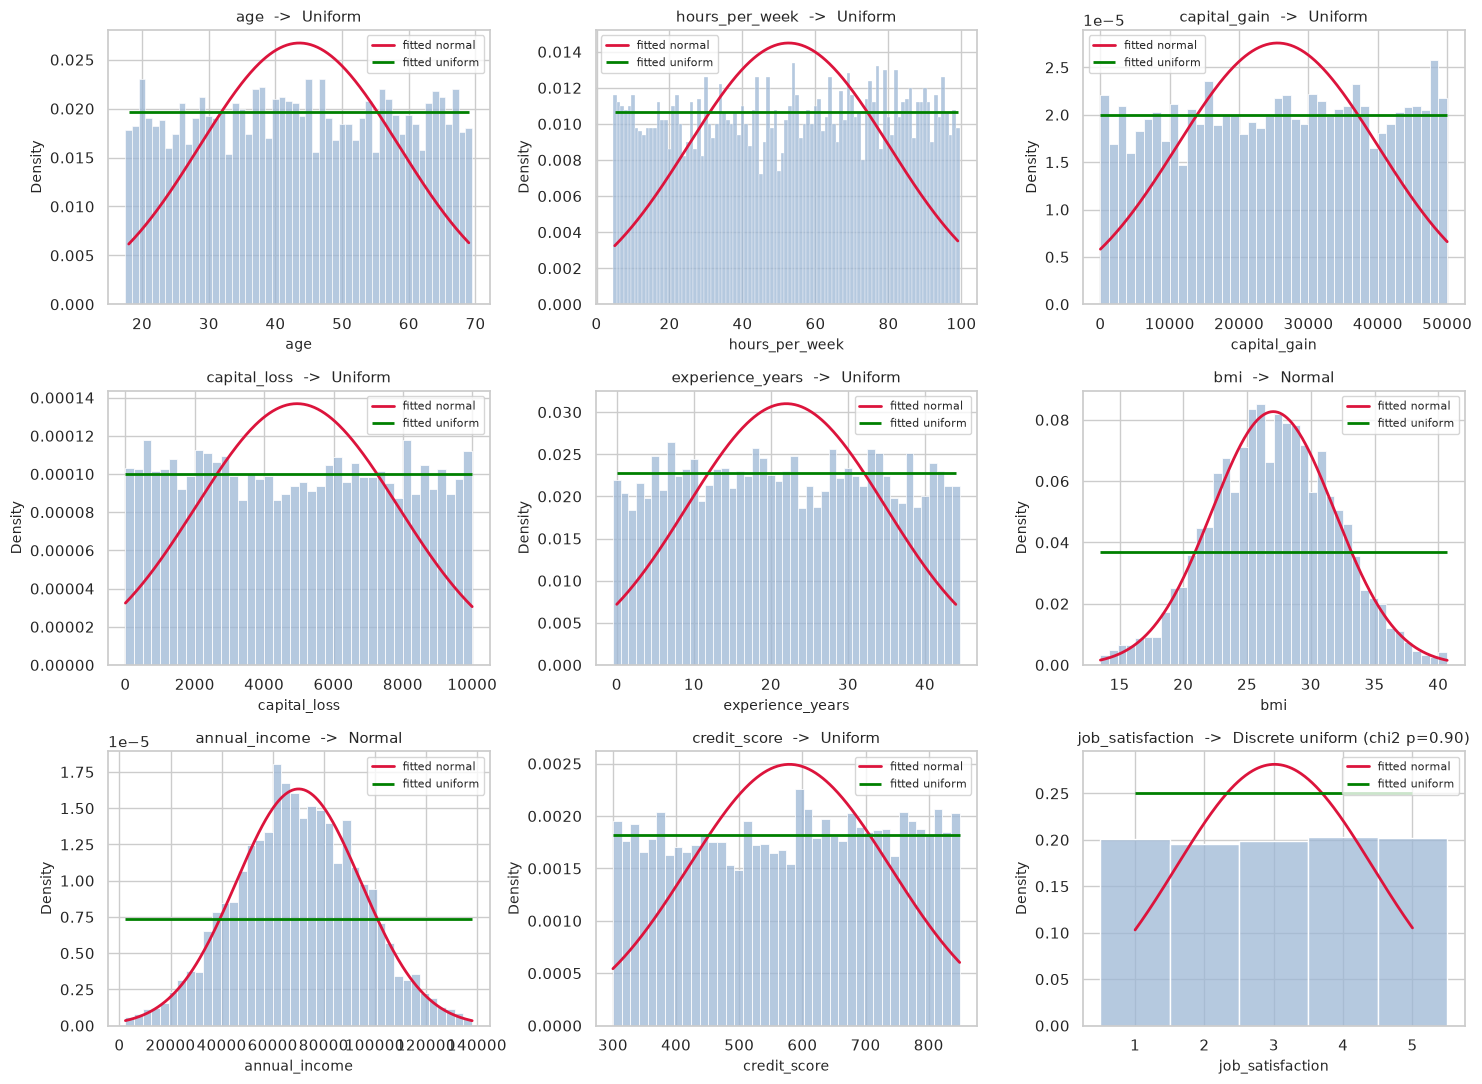

In [16]:
# visual check: overlay fitted normal (red) and uniform (green) on each histogram
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, c in zip(axes.ravel(), plot_cols):
    x = df[c]; discrete = x.nunique() <= 100 and x.dtype.kind == "i"
    sns.histplot(x, stat="density", discrete=discrete, bins=None if discrete else 40, ax=ax, color="#9db7d5", edgecolor="white")
    g = np.linspace(x.min(), x.max(), 300)
    ax.plot(g, stats.norm.pdf(g, x.mean(), x.std()), color="crimson", lw=2, label="fitted normal")
    ax.hlines(1 / (x.max() - x.min()), x.min(), x.max(), color="green", lw=2, label="fitted uniform")
    ax.set_title(f"{c}  ->  {dist_tbl.loc[c, 'label']}"); ax.legend(fontsize=8)
plt.tight_layout(); show("t1_fit_overlay")

,skew before,skew after,ex.kurt before,ex.kurt after
age,-0.00,-0.00,-1.18,-1.18
hours_per_week,2.73,-0.05,23.49,-1.21
capital_gain,-0.04,-0.04,-1.18,-1.18
capital_loss,0.02,0.02,-1.23,-1.23
experience_years,0.01,0.01,-1.19,-1.19
bmi,9.05,-0.03,138.23,-0.21
annual_income,16.07,0.00,308.12,-0.25
credit_score,-0.06,-0.05,-1.20,-1.21


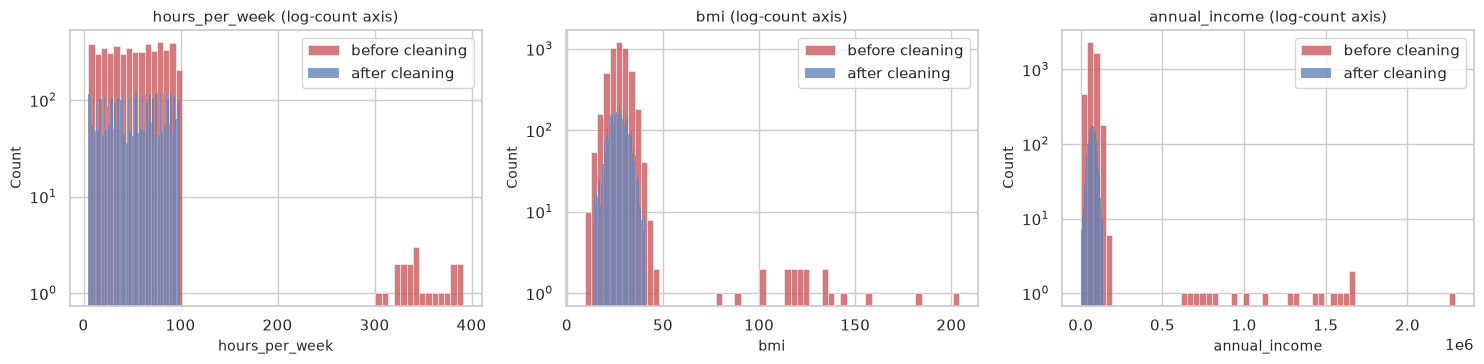

In [17]:
# Why cleaning matters for distributions: skewness / kurtosis before vs after
sk = pd.DataFrame({"skew before": df_before[num_cols].skew(), "skew after": df[num_cols].skew(),
                   "ex.kurt before": df_before[num_cols].kurt(), "ex.kurt after": df[num_cols].kurt()}).round(2)
display(sk)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, c in zip(axes, ["hours_per_week", "bmi", "annual_income"]):
    sns.histplot(df_before[c].dropna(), ax=ax, color="#c44e52", bins=60, label="before cleaning")
    sns.histplot(df[c], ax=ax, color="#4c72b0", bins=60, label="after cleaning", alpha=.7)
    ax.set_yscale("log"); ax.set_title(f"{c} (log-count axis)"); ax.legend()
plt.tight_layout(); show("t1_before_after_hist")

### Findings – distribution of each feature (cleaned data)

| Pattern | Features | Evidence |
|---|---|---|
| **Uniform** | `age` (18–69), `hours_per_week` (5–99), `capital_gain` (0–50 k), `capital_loss` (0–10 k), `experience_years` (0–44), `credit_score` (300–850) | skewness ≈ 0, excess kurtosis ≈ −1.2 (the exact value for a uniform), flat histogram, KS distance to uniform ≈ 0.02 versus ≈ 0.06–0.07 to a fitted normal |
| **Discrete uniform** | `job_satisfaction` (1–5) | the five levels have almost equal counts (chi-square p = 0.90) |
| **Normal** | `bmi` (mean 27.1, sd 4.8), `annual_income` (mean ≈ 70 k, sd ≈ 24 k) | skewness ≈ 0, bell shape, KS distance to normal ≈ 0.015 (much smaller than to uniform, ≈ 0.17). Excess kurtosis is slightly negative (≈ −0.2) because the extreme tails were removed as outliers |
| **Skewed** | none after cleaning | see the next point |
| **Multimodal** | none | every numeric feature has a single density peak. The 2 peaks reported for `capital_loss` and `experience_years` are noise on a flat density, which is why the uniform rule is applied first |

**Key observations**
* **The skewness was caused by the outliers.** Before cleaning, `hours_per_week`, `bmi` and `annual_income` had skewness 2.7, 9.1 and 16.1 and enormous kurtosis. After the impossible values were removed, skewness is ≈ 0 for all of them. Without cleaning, a reader would wrongly call these features "heavily right-skewed".
* **Categorical features** are close to uniform (`education`, `marital_status`, `smoking_status`, `physical_activity`, `loan_status`, `workclass`, `occupation`). `gender = Other` is rare (1.7 %). After merging `us`/`USA`/`U.S.`, the USA is the largest country (36 %). The target `disease_risk` is imbalanced (31 % positive), which matters for any later modelling.
* **The data looks synthetic.** The features are flat (uniform) draws and a few bell-shaped ones, which real income or hours data would not be. About 35 % of rows also have `experience_years` larger than `age − 14`. This logical inconsistency is reported here but not "fixed", because there is no basis for choosing which of the two columns is wrong.

## 1.6 Reference gallery – what each distribution type looks like
These are synthetic samples (n = 5,000) used only to illustrate the shapes that the classification rules above look for, with the real-data example for each type named in the title.

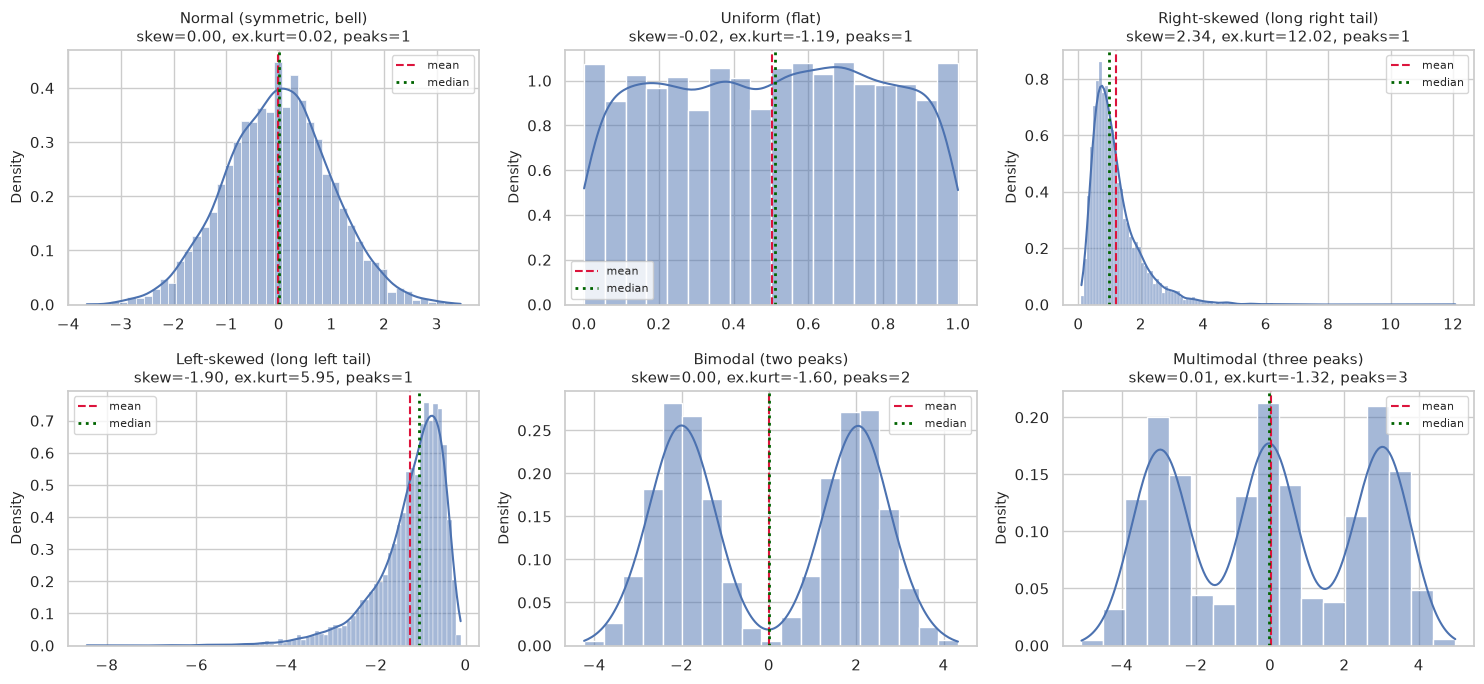

In [18]:
n = 5000
gallery = {
    "Normal (symmetric, bell)":              RNG.normal(0, 1, n),
    "Uniform (flat)":                        RNG.uniform(0, 1, n),
    "Right-skewed (long right tail)":        RNG.lognormal(0, 0.6, n),
    "Left-skewed (long left tail)":          -RNG.lognormal(0, 0.6, n),
    "Bimodal (two peaks)":                   np.r_[RNG.normal(-2, .7, n // 2), RNG.normal(2, .7, n // 2)],
    "Multimodal (three peaks)":              np.r_[RNG.normal(-3, .6, n // 3), RNG.normal(0, .6, n // 3), RNG.normal(3, .6, n - 2 * (n // 3))],
}
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (title, x) in zip(axes.ravel(), gallery.items()):
    sns.histplot(x, kde=True, stat="density", ax=ax, color="#4c72b0", edgecolor="white")
    ax.axvline(np.mean(x), color="crimson", ls="--", label=f"mean")
    ax.axvline(np.median(x), color="darkgreen", ls=":", lw=2, label="median")
    ax.set_title(f"{title}\nskew={stats.skew(x):.2f}, ex.kurt={stats.kurtosis(x):.2f}, peaks={n_modes(x)}")
    ax.legend(fontsize=8)
plt.tight_layout(); show("gallery")

---
# Task 2 – Case Study with Real Data (CIFAR-10)
## 2.1 Load the dataset
The notebook first tries `torchvision.datasets.CIFAR10` (as suggested in the assignment). If PyTorch is not installed it downloads the official CIFAR-10 archive and reads the same binary files, so the result is identical. The data is stored in a temporary folder, not in the submission folder.

In [19]:
# Reuse a local copy of CIFAR-10 if one exists (./cifar10_data or ../cifar10_data); otherwise download to a temp folder
_cands = [os.environ.get("CIFAR_DIR"), "cifar10_data", os.path.join("..", "cifar10_data")]
CIFAR_DIR = next((p for p in _cands if p and os.path.isdir(os.path.join(p, "cifar-10-batches-py"))),
                 os.path.join(tempfile.gettempdir(), "cifar10_data"))
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

def load_cifar10(root):
    """Return (x_train, y_train, x_test, y_test); images are uint8 arrays of shape (N, 32, 32, 3)."""
    try:                                                            # option 1: torchvision
        from torchvision.datasets import CIFAR10
        tr, te = CIFAR10(root, train=True, download=True), CIFAR10(root, train=False, download=True)
        return tr.data, np.array(tr.targets), te.data, np.array(te.targets)
    except ImportError:                                             # option 2: official archive
        folder = os.path.join(root, "cifar-10-batches-py")
        if not os.path.isdir(folder):
            os.makedirs(root, exist_ok=True)
            url = "https://cave.cs.toronto.edu/kriz/cifar-10-python.tar.gz"
            print("Downloading CIFAR-10 (~163 MB)...")
            path, _ = urllib.request.urlretrieve(url, os.path.join(root, "cifar.tar.gz"))
            with tarfile.open(path) as t: t.extractall(root)
        def read(files):
            xs, ys = [], []
            for fn in files:
                with open(os.path.join(folder, fn), "rb") as fh: d = pickle.load(fh, encoding="bytes")
                xs.append(d[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)); ys += d[b"labels"]
            return np.concatenate(xs), np.array(ys)
        xtr, ytr = read([f"data_batch_{i}" for i in range(1, 6)]); xte, yte = read(["test_batch"])
        return xtr, ytr, xte, yte

x_train, y_train, x_test, y_test = load_cifar10(CIFAR_DIR)
print("x_train:", x_train.shape, x_train.dtype, "| y_train:", y_train.shape)
print("x_test :", x_test.shape,  x_test.dtype,  "| y_test :", y_test.shape)
print("pixel range:", x_train.min(), "-", x_train.max())

x_train: (50000, 32, 32, 3) uint8 | y_train: (50000,)
x_test : (10000, 32, 32, 3) uint8 | y_test : (10000,)
pixel range: 0 - 255


### Structure of CIFAR-10
* **60,000 colour images**, each **32 × 32 pixels with 3 channels (R, G, B)**, pixel values are integers 0–255 (`uint8`).
* **Predefined split:** 50,000 training images (5 batches of 10,000) and 10,000 test images.
* **10 mutually exclusive classes** and the dataset is *perfectly balanced*: 5,000 training and 1,000 test images per class.
* Each image has exactly one label (0–9), so one image has 32 × 32 × 3 = **3,072 numeric values**.

,class,train images,test images
label,,,
0,airplane,5000,1000
1,automobile,5000,1000
2,bird,5000,1000
3,cat,5000,1000
4,deer,5000,1000
5,dog,5000,1000
6,frog,5000,1000
7,horse,5000,1000
8,ship,5000,1000


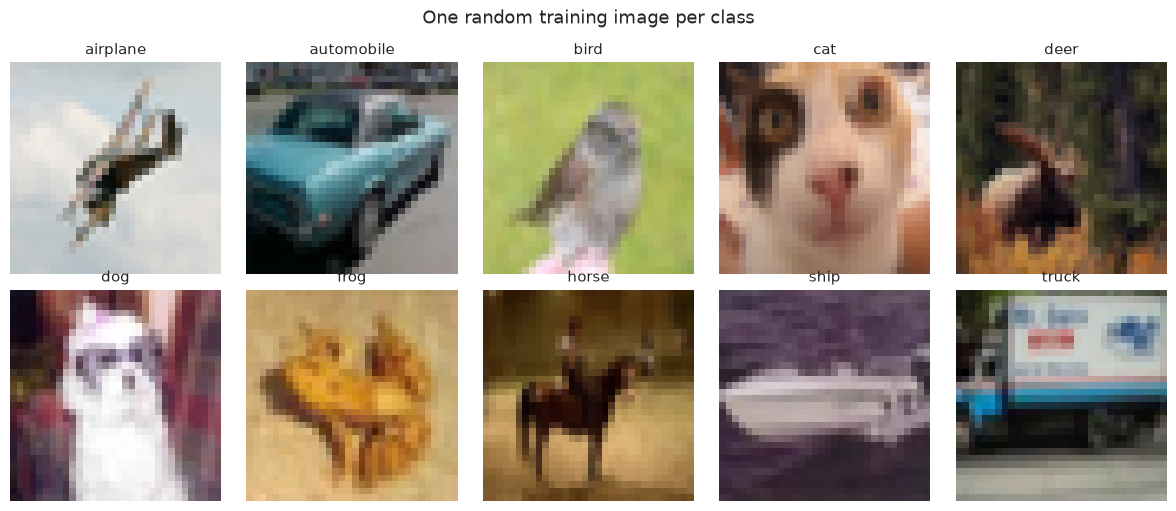

In [20]:
counts = pd.DataFrame({"class": CLASS_NAMES,
                       "label": range(10),
                       "train images": np.bincount(y_train),
                       "test images": np.bincount(y_test)}).set_index("label")
display(counts)

fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
for k, ax in enumerate(axes.ravel()):
    idx = RNG.choice(np.where(y_train == k)[0])
    ax.imshow(x_train[idx]); ax.set_title(CLASS_NAMES[k]); ax.axis("off")
plt.suptitle("One random training image per class", fontsize=13); plt.tight_layout(); show("c10_overview")

## 2.2 Select three classes
I use the three classes suggested in the assignment: **airplane (0), automobile (1, "car") and cat (3)**. They were chosen because two are man-made objects with very different typical backgrounds (sky vs. road) and one is a natural object (an animal, photographed in varied indoor and outdoor scenes). That gives a good chance of seeing *different* feature distributions between classes.

In [21]:
SEL = {"airplane": 0, "automobile": 1, "cat": 3}
COLORS = {"airplane": "#4c72b0", "automobile": "#c44e52", "cat": "#55a868"}

def subset(x, y, label): return x[y == label]
imgs_train = {n: subset(x_train, y_train, l) for n, l in SEL.items()}
imgs_test  = {n: subset(x_test,  y_test,  l) for n, l in SEL.items()}
for n in SEL: print(f"{n:11s} train: {imgs_train[n].shape}   test: {imgs_test[n].shape}")

airplane    train: (5000, 32, 32, 3)   test: (1000, 32, 32, 3)
automobile  train: (5000, 32, 32, 3)   test: (1000, 32, 32, 3)
cat         train: (5000, 32, 32, 3)   test: (1000, 32, 32, 3)


### 2.2.1 Random samples of each class

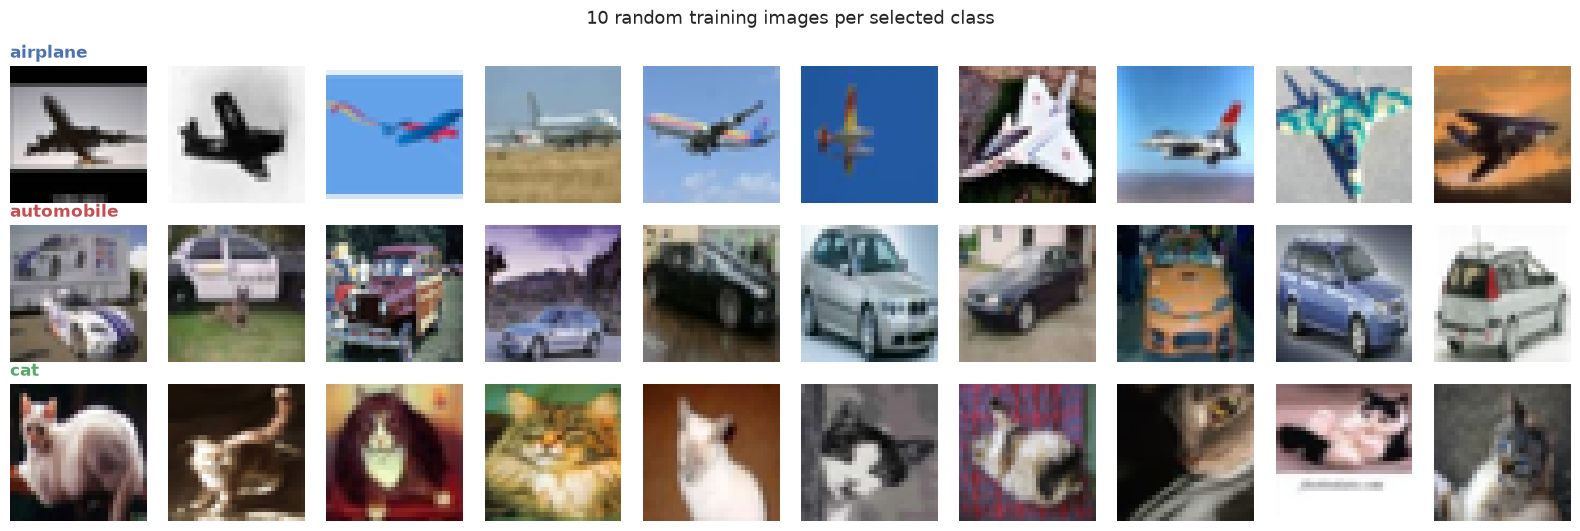

In [22]:
fig, axes = plt.subplots(3, 10, figsize=(16, 5.4))
for r, (n, arr) in enumerate(imgs_train.items()):
    pick = RNG.choice(len(arr), 10, replace=False)
    for c, i in enumerate(pick):
        axes[r, c].imshow(arr[i]); axes[r, c].axis("off")
    axes[r, 0].set_title(n, loc="left", fontsize=12, color=COLORS[n], fontweight="bold")
plt.suptitle("10 random training images per selected class", fontsize=13); plt.tight_layout(); show("c10_samples")

**Visual impression.** Airplanes are mostly a small object on a plain, bright blue/grey/white sky. Automobiles are large, centred objects in many colours on road or building backgrounds. Cats have the most variable pose, colour and background (indoor, outdoor, fur colour). We expect the airplane images to be brighter and bluer, and the cat images to be the most varied. The numerical features below test that.

### 2.2.2 Numerical feature extraction
Per image (32 × 32 × 3 pixels) I extract simple features:

| feature | meaning |
|---|---|
| `mean_R`, `mean_G`, `mean_B` | average value of each colour channel (0–255) |
| `brightness` | average of the grey-scale image (0.299 R + 0.587 G + 0.114 B) |
| `contrast` | standard deviation of the grey-scale pixels (how spread out the intensities are inside one image) |
| pixel-intensity histogram | counts of pixel values in 16 bins per channel, computed over a whole class |

In [23]:
def extract_features(arr):
    """arr: (N,32,32,3) uint8 -> DataFrame of simple per-image features."""
    a = arr.astype(np.float32)
    gray = a @ np.array([0.299, 0.587, 0.114], dtype=np.float32)       # (N,32,32)
    return pd.DataFrame({"mean_R": a[..., 0].mean((1, 2)), "mean_G": a[..., 1].mean((1, 2)),
                         "mean_B": a[..., 2].mean((1, 2)), "brightness": gray.mean((1, 2)),
                         "contrast": gray.std((1, 2))})

feats_train = {n: extract_features(a).assign(cls=n) for n, a in imgs_train.items()}
feats_test  = {n: extract_features(a).assign(cls=n) for n, a in imgs_test.items()}
ftr = pd.concat(feats_train.values(), ignore_index=True)
FEATS = ["mean_R", "mean_G", "mean_B", "brightness", "contrast"]
display(ftr.groupby("cls")[FEATS].agg(["mean", "median", "std"]).round(2).T)

cls                  airplane  automobile         cat
mean_R     mean    134.039993  120.150002  126.349998
           median  133.529999  117.089996  125.930000
           std      39.240002   31.100000   34.490002
mean_G     mean    142.880005  115.900002  116.389999
           median  142.990005  112.930000  115.519997
           std      36.150002   31.799999   33.470001
mean_B     mean    150.169998  114.040001  105.959999
           median  152.559998  111.309998  103.790001
           std      41.820000   35.320000   35.849998
brightness mean    141.070007  116.959999  118.180000
           median  140.270004  113.930000  117.129997
           std      35.650002   30.639999   32.820000
contrast   mean     46.470001   57.439999   52.259998
           median   45.590000   56.580002   51.590000
           std      16.020000   12.180000   14.650000

#### Mean RGB values per class

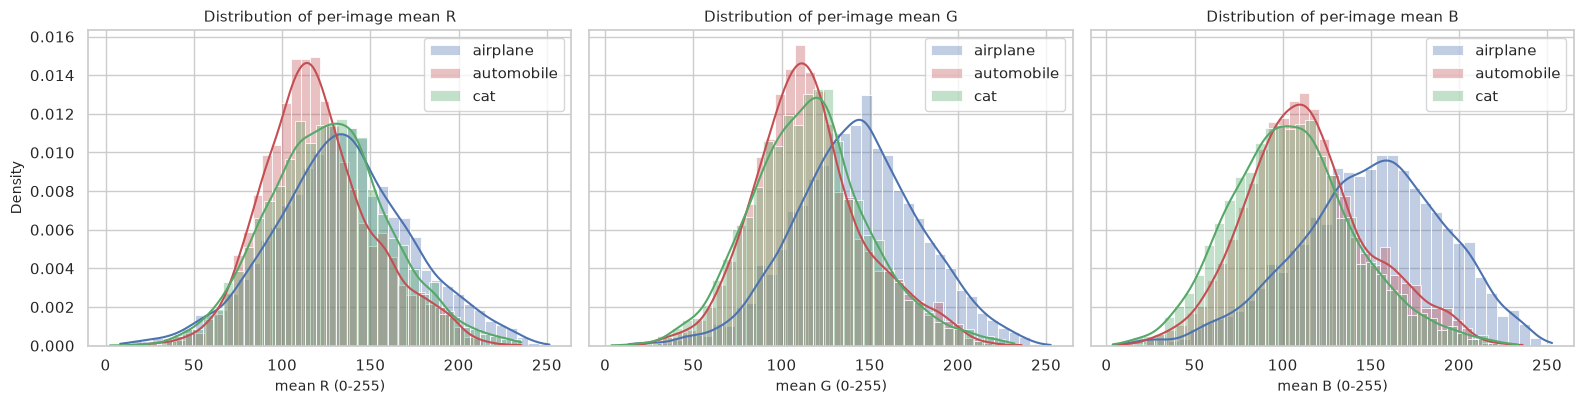

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, ch, col in zip(axes, ["mean_R", "mean_G", "mean_B"], ["R", "G", "B"]):
    for n in SEL:
        sns.histplot(ftr.loc[ftr.cls == n, ch], kde=True, stat="density", bins=40, alpha=.35,
                     color=COLORS[n], label=n, ax=ax, edgecolor=None)
    ax.set_title(f"Distribution of per-image mean {col}"); ax.set_xlabel(f"mean {col} (0-255)"); ax.legend()
plt.tight_layout(); show("c10_mean_rgb")

#### Brightness and contrast per class

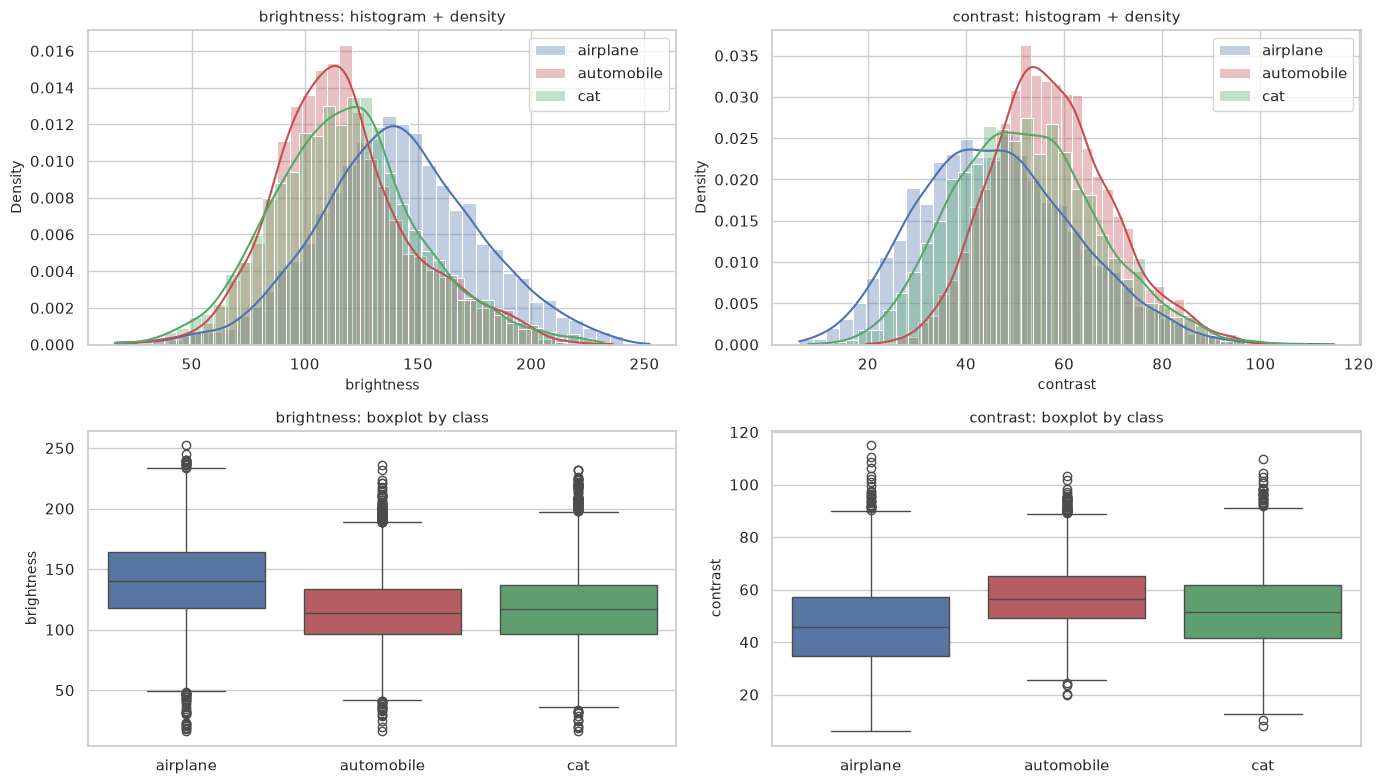

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for j, ft in enumerate(["brightness", "contrast"]):
    for n in SEL:
        sns.histplot(ftr.loc[ftr.cls == n, ft], kde=True, stat="density", bins=40, alpha=.35,
                     color=COLORS[n], label=n, ax=axes[0, j], edgecolor=None)
    axes[0, j].set_title(f"{ft}: histogram + density"); axes[0, j].legend()
    sns.boxplot(data=ftr, x="cls", y=ft, order=list(SEL), palette=COLORS, ax=axes[1, j])
    axes[1, j].set_title(f"{ft}: boxplot by class"); axes[1, j].set_xlabel("")
plt.tight_layout(); show("c10_bright_contrast")

#### Pixel-intensity histograms (all pixels of a class, per channel)

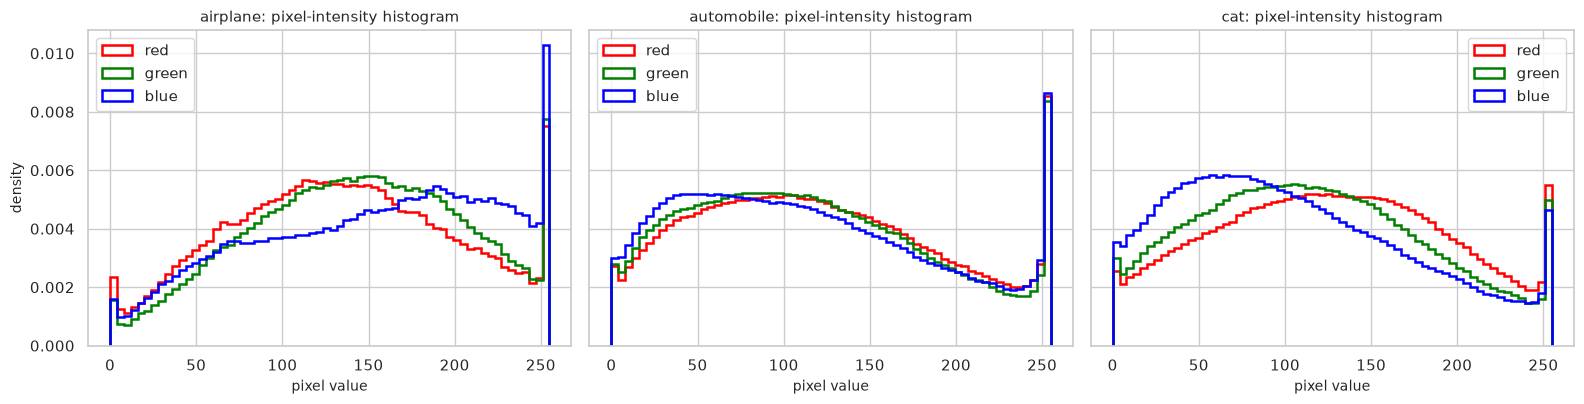

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, n in zip(axes, SEL):
    for ch, col in enumerate(["red", "green", "blue"]):
        vals = imgs_train[n][..., ch].ravel()
        ax.hist(vals, bins=64, range=(0, 255), density=True, histtype="step", lw=1.8, color=col, label=col)
    ax.set_title(f"{n}: pixel-intensity histogram"); ax.set_xlabel("pixel value"); ax.legend()
axes[0].set_ylabel("density")
plt.tight_layout(); show("c10_pixel_hist")

### 2.2.3 Distribution analysis of the extracted features

In [27]:
# Reuse the same statistics + decision rules as in Task 1
rows = []
for n in SEL:
    for ft in FEATS:
        r = describe_distribution(ftr.loc[ftr.cls == n, ft], ft); r["class"] = n
        # D'Agostino-Pearson normality test (very sensitive for n = 5000, reported for completeness)
        r["normaltest p"] = stats.normaltest(ftr.loc[ftr.cls == n, ft]).pvalue
        rows.append(r)
cifar_dist = pd.DataFrame(rows).set_index(["class", "feature"])
display(cifar_dist[["mean", "median", "skew", "ex.kurtosis", "KS D (normal)", "# KDE peaks", "normaltest p", "label"]].round(3))

mean   median   skew  ex.kurtosis  KS D (normal)  \
class      feature                                                           
airplane   mean_R      134.042  133.531  0.011        0.019          0.022   
           mean_G      142.884  142.989 -0.081        0.101          0.014   
           mean_B      150.171  152.561 -0.324       -0.077          0.026   
           brightness  141.071  140.266 -0.012        0.122          0.019   
           contrast     46.473   45.593  0.349       -0.048          0.031   
automobile mean_R      120.152  117.094  0.401        0.199          0.051   
           mean_G      115.905  112.932  0.420        0.331          0.057   
           mean_B      114.036  111.308  0.334        0.056          0.046   
           brightness  116.962  113.934  0.508        0.402          0.065   
           contrast     57.444   56.582  0.337        0.086          0.031   
cat        mean_R      126.348  125.930  0.156        0.029          0.017   
           mean_G      116.385  115.522  0.299        0.298          0.034   
           mean_B      105.962  103.791  0.359        0.169          0.030   
           brightness  118.176  117.133  0.307        0.313          0.035   
           contrast     52.256   51.586  0.282       -0.088          0.024   

                       # KDE peaks  normaltest p                label  
class      feature                                                     
airplane   mean_R                1         0.905               Normal  
           mean_G                1         0.023               Normal  
           mean_B                1         0.000               Normal  
           brightness            1         0.215               Normal  
           contrast              1         0.000               Normal  
automobile mean_R                1         0.000  Other / flat-tailed  
           mean_G                1         0.000  Other / flat-tailed  
           mean_B                1         0.000               Normal  
           brightness            1         0.000         Right-skewed  
           contrast              1         0.000               Normal  
cat        mean_R                1         0.000               Normal  
           mean_G                1         0.000               Normal  
           mean_B                1         0.000               Normal  
           brightness            1         0.000               Normal  
           contrast              1         0.000               Normal

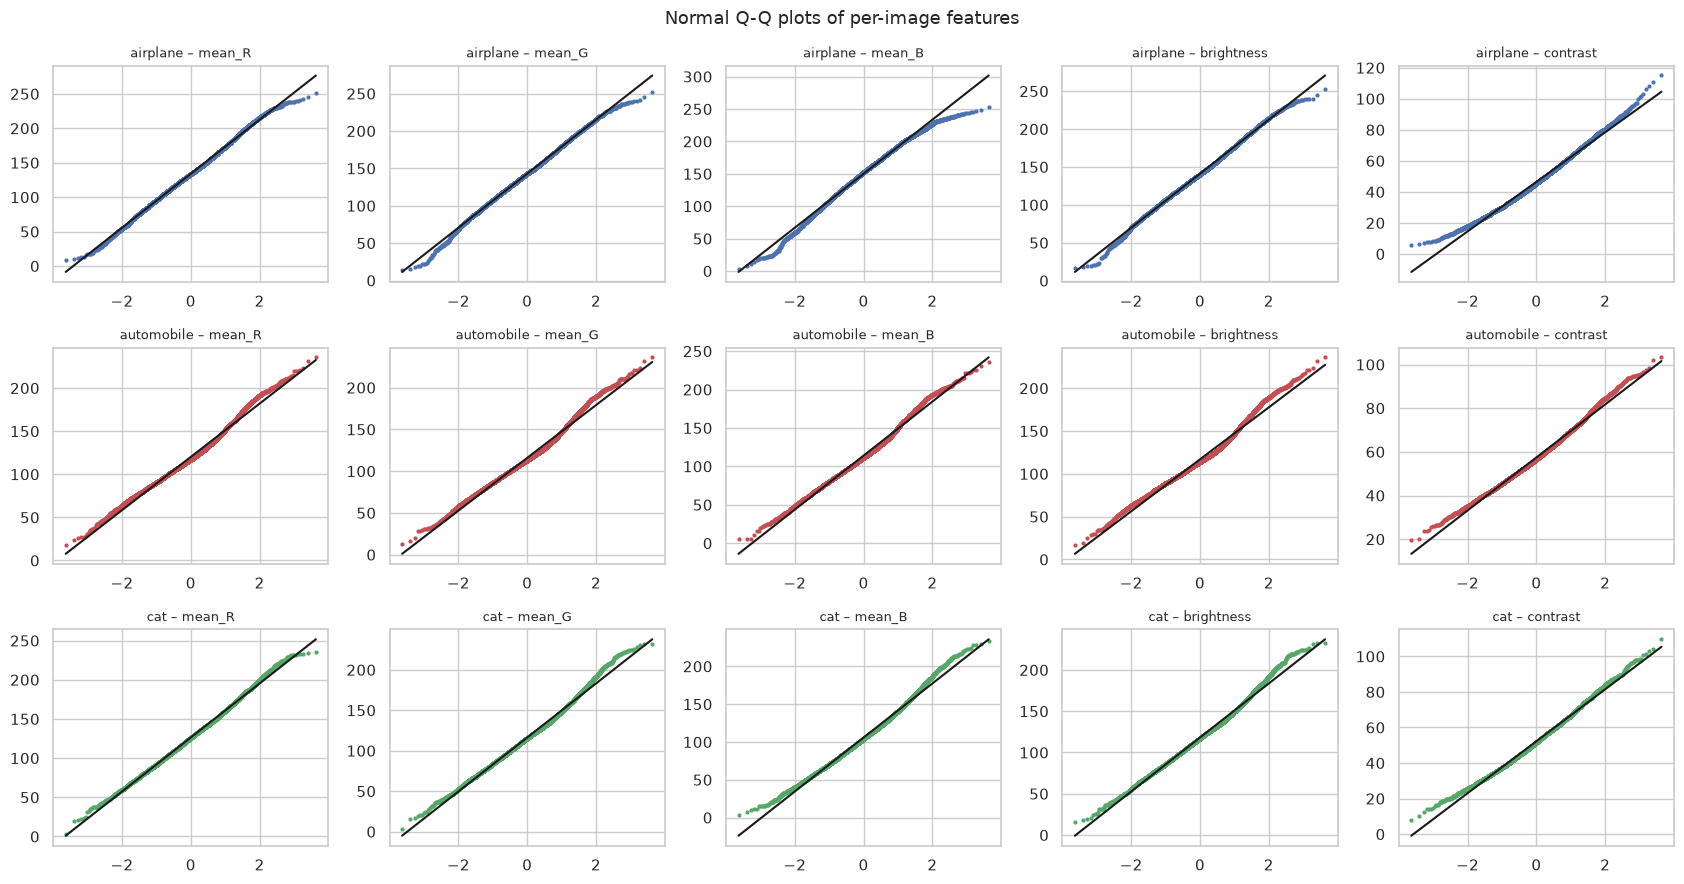

In [28]:
# Q-Q plots against the normal distribution: points on the red line = normal
fig, axes = plt.subplots(3, 5, figsize=(17, 9))
for i, n in enumerate(SEL):
    for j, ft in enumerate(FEATS):
        stats.probplot(ftr.loc[ftr.cls == n, ft], dist="norm", plot=axes[i, j])
        axes[i, j].get_lines()[0].set(markersize=2, color=COLORS[n]); axes[i, j].get_lines()[1].set(color="k")
        axes[i, j].set_title(f"{n} – {ft}", fontsize=9); axes[i, j].set_xlabel(""); axes[i, j].set_ylabel("")
plt.suptitle("Normal Q-Q plots of per-image features", fontsize=13); plt.tight_layout(); show("c10_qq")

### Findings – feature distributions in CIFAR-10

**Per-image features (mean R/G/B, brightness, contrast)**
* All of them are **unimodal and roughly bell-shaped**. This is expected: each value is the average of 1,024 pixels, so the Central Limit Theorem pushes it towards a normal distribution.
* The shape is not perfectly normal. **Airplanes** are the most symmetric (skew ≈ 0 for R, G and brightness), and their blue channel is slightly **left-skewed** (−0.32) because the bright sky pushes the values against the ceiling of 255. **Automobiles** and **cats** are mildly **right-skewed** (≈ 0.3–0.5; automobile brightness 0.51): values are bounded below by 0, most images are mid-to-dark, and a tail of very bright images stretches to the right.
* The D'Agostino normality test rejects normality for most of them (p < 0.05). With 5,000 images per class even a small skew is "significant", so the Q-Q plots and skewness values are the more useful evidence: the points follow the line in the middle and bend away only in the tails.
* **The classes differ clearly.** Airplanes are brighter (mean brightness ≈ 141 versus ≈ 117 for automobiles and ≈ 118 for cats) and bluer (B − R ≈ +16). Cats are the warmest class (R > G > B, B − R ≈ −20). Automobiles have the highest contrast (≈ 57), consistent with strong object/background differences. Automobile and cat are similar in average colour (KS distance 0.05–0.13) but separate on contrast (0.19).

**Pixel-intensity histograms** are *not* normal. They are broad, asymmetric and have a **sharp spike at 255** (saturated white pixels, strongest in the airplane blue channel) and a smaller one near 0. The airplane blue histogram is left-skewed and the cat blue histogram is right-skewed. These spikes (clipping at the 0–255 limits) are a reminder that bounded data are rarely perfectly normal.

## 2.3 Is CIFAR-10 IID or Non-IID?
**Definition.** Data is **IID** (independent and identically distributed) if every sample is drawn independently from *one and the same* distribution. It is **Non-IID** when samples depend on each other, or when different parts of the data come from different distributions (e.g. one client holds only cats, another only airplanes).

IID-ness is a property of *how the data is sampled and split*, not only of the dataset, so I test it in three experiments:

1. **Train vs. test split** – do the two splits come from the same distribution? (two-sample KS test per feature, within each class and for the mixed data)
2. **Class vs. class** – are the feature distributions of different classes identical?
3. **Simulated partitioning into 5 "clients"** – random split vs. split by class, compared by label distribution and feature distribution.

In [29]:
# Experiment 1 – train vs test of the SAME class (should look identical if the split is IID)
rows = []
for n in SEL:
    for ft in FEATS:
        ks = stats.ks_2samp(feats_train[n][ft], feats_test[n][ft])
        rows.append({"class": n, "feature": ft, "KS D": ks.statistic, "p-value": ks.pvalue})
e1 = pd.DataFrame(rows)
display(e1.pivot(index="feature", columns="class", values="KS D").round(3).rename_axis(columns="KS D (train vs test)"))
print("Share of (class, feature) pairs with p > 0.05 (cannot tell train from test):",
      f"{(e1['p-value'] > 0.05).mean():.0%}")

KS D (train vs test),airplane,automobile,cat
feature,,,
brightness,0.039,0.030,0.028
contrast,0.042,0.027,0.022
mean_B,0.047,0.019,0.030
mean_G,0.040,0.023,0.023
mean_R,0.028,0.023,0.035


Share of (class, feature) pairs with p > 0.05 (cannot tell train from test): 93%


In [30]:
# Experiment 2 – class vs class (should differ strongly if classes are NOT identically distributed)
from itertools import combinations
rows = []
for a, b in combinations(SEL, 2):
    for ft in FEATS:
        ks = stats.ks_2samp(feats_train[a][ft], feats_train[b][ft])
        rows.append({"pair": f"{a} vs {b}", "feature": ft, "KS D": ks.statistic, "p-value": ks.pvalue})
e2 = pd.DataFrame(rows)
display(e2.pivot(index="feature", columns="pair", values="KS D").round(3).rename_axis(columns="KS D (class vs class)"))
print("Pairs with p < 0.001 (clearly different):", f"{(e2['p-value'] < 1e-3).mean():.0%}")

KS D (class vs class),airplane vs automobile,airplane vs cat,automobile vs cat
feature,,,
brightness,0.347,0.300,0.070
contrast,0.342,0.165,0.190
mean_B,0.417,0.478,0.099
mean_G,0.371,0.337,0.045
mean_R,0.214,0.096,0.125


Pairs with p < 0.001 (clearly different): 100%


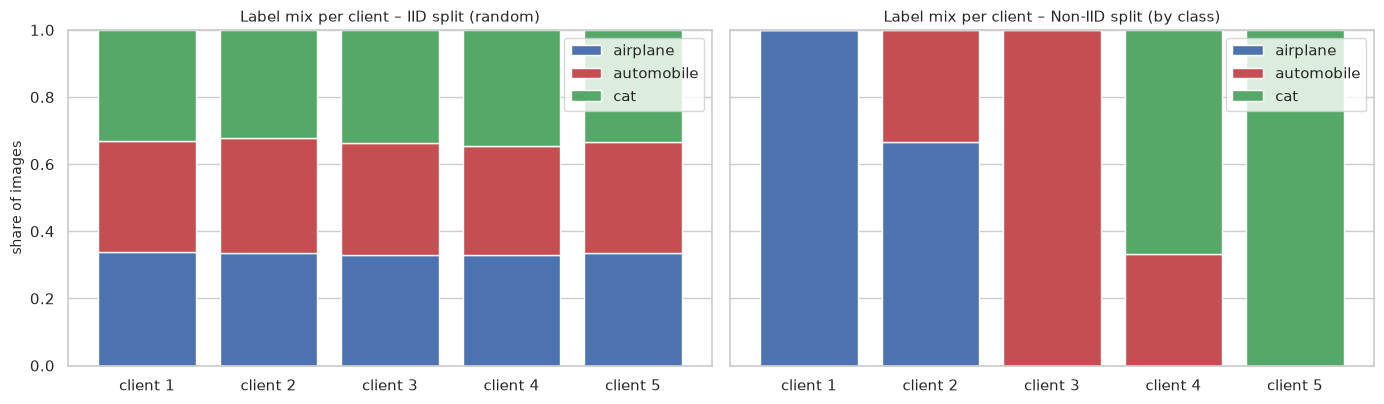

Largest KS distance between a client and the overall data (brightness):
  IID split     : 0.021
  Non-IID split : 0.213


In [31]:
# Experiment 3 – split the 3-class training data (15,000 images) over 5 clients, two ways
labels = np.r_[[0]*5000, [1]*5000, [2]*5000]                  # 0 airplane, 1 automobile, 2 cat
order  = list(SEL)
F = pd.concat([feats_train[n] for n in order], ignore_index=True)

perm = RNG.permutation(len(F))
iid_clients = np.array_split(perm, 5)                         # IID: random shuffle, then cut
non_iid_clients = np.array_split(np.arange(len(F)), 5)        # Non-IID: sorted by class, then cut

def label_dist(clients):
    return pd.DataFrame([np.bincount(labels[idx], minlength=3) / len(idx) for idx in clients],
                        columns=order, index=[f"client {i+1}" for i in range(5)])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, (title, cl) in zip(axes, [("IID split (random)", iid_clients), ("Non-IID split (by class)", non_iid_clients)]):
    label_dist(cl).plot(kind="bar", stacked=True, ax=ax, color=[COLORS[n] for n in order], width=.8)
    ax.set_title(f"Label mix per client – {title}"); ax.set_ylabel("share of images"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); show("c10_clients")

def max_ks(clients, ft="brightness"):
    """Largest KS distance between any client's feature distribution and the overall one."""
    return max(stats.ks_2samp(F.loc[idx, ft], F[ft]).statistic for idx in clients)
print("Largest KS distance between a client and the overall data (brightness):")
print(f"  IID split     : {max_ks(iid_clients):.3f}")
print(f"  Non-IID split : {max_ks(non_iid_clients):.3f}")

### Conclusion – IID or Non-IID?

| Experiment | Result | Meaning |
|---|---|---|
| 1. Train vs test (same class) | KS distance ≤ 0.047; 14 of 15 feature/class pairs are indistinguishable at the 5 % level (about one in 15 is expected to fail by chance) | the split behaves as **identically distributed** |
| 2. Class vs class | all 15 pairs differ (p < 0.001), KS distance up to 0.48 | different classes come from **different distributions** |
| 3. Five clients | random split: label mix ≈ 33 % each, max KS distance 0.021. Split by class: each client holds one class, max KS distance 0.213 | the way the data is partitioned decides IID or Non-IID |

**Answer.** CIFAR-10 *taken as a whole and shuffled* can be treated as **IID**: the images are separate photographs and the training and test sets are drawn from the same distribution (Experiment 1), so a random mini-batch or a random split is a fair sample. It is **not identically distributed across classes** (Experiment 2). Therefore any partition that follows the labels, such as one class per client in federated learning, a class-ordered file read without shuffling, or training on only some classes, is **Non-IID** (Experiment 3). In my three-class experiment the pooled data is IID only after random shuffling.

*Caveat:* independence is an assumption and was not proven. CIFAR-10 was filtered from a larger web collection and may contain a few near-duplicate images, and the tests above only examine the five simple features.

---
# 3. Summary

* **Dataset 1:** 49 duplicate rows were removed; the text columns hiding `unknown` were converted; three spellings of the USA were merged; 12 negative incomes and the impossible outliers (hours up to 391, BMI up to 204, income up to 2.3 million) were set to missing; and all missing values were imputed by sampling the observed values (or an `Unknown` category) so distribution shapes were preserved.
* **Dataset 1 distributions:** seven numeric features are uniform, `bmi` and `annual_income` are normal, none is skewed or multimodal after cleaning. The skew seen before cleaning was an artefact of the outliers.
* **CIFAR-10:** per-image mean colour, brightness and contrast are unimodal, roughly normal with mild skew, and clearly different between airplane, automobile and cat. Pixel histograms are broad with a spike at 255.
* **IID:** shuffled CIFAR-10 is IID (train and test match), but the classes follow different distributions, so label-based partitions are Non-IID.
* **Why distributions matter:** they decide which summary statistic is meaningful (mean or median), which tests and models are valid, how to detect outliers and impute values without distortion, whether a transformation is needed, and whether training data represents the data a model will meet.